# Notebook 03 — GRU baselines (Local + Centralized + Federated)

**Purpose.** This notebook implements the three GRU baselines required by the
thesis:

- **Local GRU** — one model per client, trained on that client's data only.
- **Centralized GRU** — one model trained on the pooled data from all clients.
- **Federated GRU** — one global model trained with FedAvg, with a FedProx
  extension that tests whether proximal regularization mitigates client drift.

The three baselines share the same architecture, hyperparameters,
preprocessing tensors, and evaluation protocol. They differ only in the
training strategy. This isolates the effect of the training strategy from
the effect of the model.

**Reporting structure.** Each baseline is presented in two phases: first a
training-behavior analysis (per-epoch or per-round trajectories with summary
tables and curves), then a test-set evaluation (accuracy, per-class metrics,
confusion-matrix-derived quantities). The two phases are reported in this
order because learning dynamics inform the interpretation of generalization.

**Inputs.** Preprocessed sequence tensors saved by Notebook 02
(`<client>_stage1_sequences.npz` + `preprocess_manifest.json`).

**Outputs.** Per-client training summaries and curves, per-client test
metrics, per-class reports, modal-density-stratified results, saved model
state-dicts, and a manifest summarizing every selection decision.

## Section 0 — Setup

In [5]:
# 0.1 — Imports
import os, json, time, random, copy, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

print("Imports ready.")

Imports ready.


In [6]:
# 0.2 — Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU   : {torch.cuda.get_device_name(0)}")

Device: cuda
GPU   : Tesla T4


In [7]:
# 0.3 — Paths (auto-discover Notebook 02 outputs)
candidate_dirs = []
for root, dirs, files in os.walk("/kaggle/input"):
    if "preprocess_manifest.json" in files:
        candidate_dirs.append(Path(root))

assert candidate_dirs, (
    "No preprocess_manifest.json found under /kaggle/input. "
    "Attach Notebook 02 outputs as a Kaggle dataset."
)

PREPROCESS_DIR = candidate_dirs[0]
TENSOR_DIR     = PREPROCESS_DIR / "tensors"
MANIFEST_PATH  = PREPROCESS_DIR / "preprocess_manifest.json"

OUTPUT_DIR = Path("/kaggle/working/gru_baselines")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(MODELS_DIR := OUTPUT_DIR / "models").mkdir(exist_ok=True)
(AUDIT_DIR  := OUTPUT_DIR / "audit").mkdir(exist_ok=True)
(PREDS_DIR  := OUTPUT_DIR / "predictions").mkdir(exist_ok=True)

print(f"Preprocess dir: {PREPROCESS_DIR}")
print(f"Output dir    : {OUTPUT_DIR}")

Preprocess dir: /kaggle/input/datasets/sarahaddouda/preprocess-outputs
Output dir    : /kaggle/working/gru_baselines


In [8]:
# 0.4 — Constants (frozen — must match Notebook 02)
ACTIVE_CLIENTS = ["England", "Ireland", "USA"]
FEATURE_COLS   = ["NH3", "BOD", "DO", "PO4", "pH", "Temp", "Nitrogen", "Nitrate"]
SPLITS         = ["train", "val", "test"]

WINDOW    = 12
N_FEATS   = len(FEATURE_COLS)
N_CLASSES = 5

CCME_CLASS_ORDER = ["Excellent", "Good", "Fair", "Marginal", "Poor"]
INT_TO_CLASS = {i: c for i, c in enumerate(CCME_CLASS_ORDER)}
CLASS_NAMES  = CCME_CLASS_ORDER

print(f"Active clients : {ACTIVE_CLIENTS}")
print(f"Features ({N_FEATS}): {FEATURE_COLS}")
print(f"Window length  : {WINDOW}")
print(f"Classes ({N_CLASSES}) : {CLASS_NAMES}")

Active clients : ['England', 'Ireland', 'USA']
Features (8): ['NH3', 'BOD', 'DO', 'PO4', 'pH', 'Temp', 'Nitrogen', 'Nitrate']
Window length  : 12
Classes (5) : ['Excellent', 'Good', 'Fair', 'Marginal', 'Poor']


## Section 1 — Load preprocessed tensors

Load the per-client `.npz` files written by Notebook 02. Each archive contains
the train, validation and test sequence tensors for one client. The mask
tensor is the modal-value proxy used later in Section 11 for stratified
evaluation.

In [9]:
# 1.1 — Load .npz archives
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    preprocess_manifest = json.load(f)

data = {}
for client in ACTIVE_CLIENTS:
    npz_path = TENSOR_DIR / f"{client.lower()}_stage1_sequences.npz"
    assert npz_path.exists(), f"Missing tensor file: {npz_path}"

    archive = np.load(npz_path, allow_pickle=True)
    data[client] = {}
    for split in SPLITS:
        data[client][split] = {
            "X":            archive[f"X_{split}"],
            "y":            archive[f"y_{split}"],
            "mask":         archive[f"mask_{split}"],
            "site_ids":     archive[f"site_ids_{split}"],
            "target_dates": archive[f"target_dates_{split}"],
        }
    archive.close()

print("Loaded tensors:")
for client in ACTIVE_CLIENTS:
    sizes = " | ".join(
        f"{s}={data[client][s]['X'].shape[0]:>6,}"
        for s in SPLITS
    )
    print(f"  [{client:<8}] {sizes}")

Loaded tensors:
  [England ] train=76,530 | val= 8,490 | test=11,942
  [Ireland ] train=27,778 | val= 4,296 | test= 5,887
  [USA     ] train=30,222 | val= 1,770 | test= 1,979


In [10]:
# 1.2 — Verify against Notebook 02 manifest
verify_rows = []
for client in ACTIVE_CLIENTS:
    expected_counts = preprocess_manifest["sequence_counts"][client]
    for split in SPLITS:
        X = data[client][split]["X"]
        y = data[client][split]["y"]
        mask = data[client][split]["mask"]

        n_loaded   = X.shape[0]
        n_expected = expected_counts[split]
        ok = (
            X.shape == mask.shape
            and X.ndim == 3
            and X.shape[1:] == (WINDOW, N_FEATS)
            and y.shape == (n_loaded,)
            and n_loaded == n_expected
            and np.isfinite(X).all()
            and y.min() >= 0
            and y.max() < N_CLASSES
        )
        verify_rows.append({
            "Client": client,
            "Split":  split,
            "N_loaded":   n_loaded,
            "N_expected": n_expected,
            "X_shape":  str(tuple(X.shape)),
            "y_range":  f"[{int(y.min())}, {int(y.max())}]",
            "OK": "ok" if ok else "FAIL",
        })

verify_df = pd.DataFrame(verify_rows)
display(verify_df)

assert (verify_df["OK"] == "ok").all(), "Tensor verification failed."
print("\nAll tensors verified against the manifest.")

,Client,Split,N_loaded,N_expected,X_shape,y_range,OK
0,England,train,76530,76530,"(76530, 12, 8)","[0, 4]",ok
1,England,val,8490,8490,"(8490, 12, 8)","[0, 4]",ok
2,England,test,11942,11942,"(11942, 12, 8)","[0, 4]",ok
3,Ireland,train,27778,27778,"(27778, 12, 8)","[0, 4]",ok
4,Ireland,val,4296,4296,"(4296, 12, 8)","[0, 3]",ok
5,Ireland,test,5887,5887,"(5887, 12, 8)","[0, 2]",ok
6,USA,train,30222,30222,"(30222, 12, 8)","[0, 3]",ok
7,USA,val,1770,1770,"(1770, 12, 8)","[0, 2]",ok
8,USA,test,1979,1979,"(1979, 12, 8)","[0, 1]",ok



All tensors verified against the manifest.


## Section 2 — Architecture and hyperparameter rationale

Before defining the model, we record the design choices and the reasoning
behind each one. These choices are fixed across all three baselines so that
the comparison isolates the effect of the training strategy.

### Architecture

| Choice | Value | Reason |
|---|---|---|
| Model family | GRU | Short sequences (L = 12). Empirically equivalent to LSTM with fewer parameters and faster training (Chung et al., 2014). |
| Hidden size | 64 | Small model (~14k parameters). Appropriate for the per-client training-set sizes (~25k–80k sequences). |
| Number of layers | 1 | Multi-layer GRUs add expressivity mainly on longer sequences. |
| Dropout | 0.2 | Standard sequence-classifier regularization. |
| Read-out | last hidden state → Linear(64 → 5) | Standard sequence-to-class head. |

### Training

| Choice | Value | Reason |
|---|---|---|
| Loss | class-weighted cross-entropy | Required by the class imbalance documented in Notebook 02. |
| Optimizer | Adam | Robust default for sequence models. |
| Learning rate (local + centralized) | 1e-3 | Standard Adam value; converges in well under 50 epochs. |
| Learning rate (federated) | 5e-4 | Reduced because FedAvg aggregation amplifies effective step size. |
| Weight decay | 1e-4 | Mild L2 regularization. |
| Gradient clip norm | 1.0 | Protects against RNN gradient explosions. |
| Batch size | 256 | Fits comfortably on a Kaggle GPU; stable gradient estimate. |
| Max epochs | 50 | All clients converge well before 50. |
| Early-stopping patience | 10 | Tolerates short plateaus; halts on real divergence. |
| Selection metric | macro-F1 | Class-imbalance-aware; consistent with reported test metrics. |

### Federated specifics

| Choice | Value | Reason |
|---|---|---|
| Algorithm | FedAvg (McMahan et al., 2017) | Canonical FL baseline. |
| Aggregation weights | proportional to client training-set size | Standard FedAvg weighting. |
| Local epochs per round | 1 | Reduces client drift in non-IID settings. |
| Communication rounds | 30 | Enough to observe convergence or divergence pattern. |
| Drift-control extension | FedProx (Li et al., 2018) | Tested across µ ∈ {0.01, 0.001, 0.0001}. |

The selection metric for the federated model is **mean of per-client validation
macro-F1**, not pooled validation macro-F1. The mean-of-clients criterion
gives each client equal weight in model selection, which is consistent with
the federated principle.

## Section 3 — Model and shared utilities

Define the GRU architecture and the training/evaluation utilities once.
Every baseline in this notebook uses these same objects.

In [11]:
# 3.1 — SequenceDataset
class SequenceDataset(Dataset):
    """Wraps (X, y) numpy arrays for PyTorch."""
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [12]:
# 3.2 — GRU classifier
class GRUClassifier(nn.Module):
    """Single-layer GRU + dropout + linear classification head."""
    def __init__(self, input_size=N_FEATS, hidden_size=64,
                 num_layers=1, num_classes=N_CLASSES, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        _, h_n = self.gru(x)
        h_last = h_n[-1]
        h_last = self.dropout(h_last)
        return self.classifier(h_last)


MODEL_CONFIG = {
    "input_size":  N_FEATS,
    "hidden_size": 64,
    "num_layers":  1,
    "num_classes": N_CLASSES,
    "dropout":     0.2,
}

TRAIN_CONFIG = {
    "batch_size":               256,
    "learning_rate":            1e-3,
    "weight_decay":             1e-4,
    "max_epochs":               50,
    "early_stopping_patience":  10,
    "lr_scheduler_patience":    3,
    "lr_scheduler_factor":      0.5,
    "gradient_clip_norm":       1.0,
    "primary_metric":           "macro_f1",
    "max_class_weight":         10.0,
}

def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

n_params = count_trainable_parameters(GRUClassifier(**MODEL_CONFIG))
print(f"GRUClassifier defined.")
print(f"  Trainable parameters: {n_params:,}")
print(f"  Architecture: {MODEL_CONFIG}")

GRUClassifier defined.
  Trainable parameters: 14,533
  Architecture: {'input_size': 8, 'hidden_size': 64, 'num_layers': 1, 'num_classes': 5, 'dropout': 0.2}


In [13]:
# 3.3 — Loaders and metrics
def make_loader(X, y, batch_size, shuffle):
    ds = SequenceDataset(X, y)
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )


def compute_metrics(y_true, y_pred):
    return {
        "accuracy":          accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1":          f1_score(
            y_true, y_pred,
            labels=list(range(N_CLASSES)),
            average="macro", zero_division=0,
        ),
        "weighted_f1":       f1_score(
            y_true, y_pred,
            labels=list(range(N_CLASSES)),
            average="weighted", zero_division=0,
        ),
    }


def compute_test_metrics(y_true, y_pred):
    """Test metrics including present-class macro-F1."""
    present_labels = sorted(np.unique(y_true).tolist())
    return {
        "accuracy":                 accuracy_score(y_true, y_pred),
        "balanced_accuracy":        balanced_accuracy_score(y_true, y_pred),
        "macro_f1_all_classes":     f1_score(
            y_true, y_pred,
            labels=list(range(N_CLASSES)),
            average="macro", zero_division=0,
        ),
        "macro_f1_present_classes": f1_score(
            y_true, y_pred,
            labels=present_labels,
            average="macro", zero_division=0,
        ),
        "weighted_f1":              f1_score(
            y_true, y_pred,
            labels=list(range(N_CLASSES)),
            average="weighted", zero_division=0,
        ),
        "present_classes":          ", ".join(INT_TO_CLASS[i] for i in present_labels),
    }

In [14]:
# 3.4 — Class-weight helper
def inverse_frequency_weights(y, cap=TRAIN_CONFIG["max_class_weight"]):
    """Inverse-frequency class weights, mean-normalized, capped."""
    counts = np.bincount(y, minlength=N_CLASSES).astype(np.float64)
    N = counts.sum()
    w = np.zeros(N_CLASSES, dtype=np.float64)
    present = counts > 0
    w[present] = N / (present.sum() * counts[present])
    w[present] = w[present] / w[present].mean()
    w = np.minimum(w, cap)
    if (w > 0).any():
        w[w > 0] = w[w > 0] / w[w > 0].mean()
    return w.astype(np.float32), counts.astype(int)

In [15]:
# 3.5 — Train / eval functions
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    total_samples = 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), TRAIN_CONFIG["gradient_clip_norm"]
        )
        optimizer.step()
        bs = X_batch.size(0)
        total_loss    += loss.item() * bs
        total_samples += bs
    return total_loss / total_samples


def evaluate(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    all_true, all_pred = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            logits = model(X_batch)
            if criterion is not None:
                loss = criterion(logits, y_batch)
                total_loss    += loss.item() * X_batch.size(0)
                total_samples += X_batch.size(0)
            preds = torch.argmax(logits, dim=1)
            all_true.append(y_batch.cpu().numpy())
            all_pred.append(preds.cpu().numpy())
    y_true = np.concatenate(all_true)
    y_pred = np.concatenate(all_pred)
    out = compute_metrics(y_true, y_pred)
    out["loss"] = total_loss / total_samples if total_samples > 0 else float("nan")
    out["y_true"], out["y_pred"] = y_true, y_pred
    return out


def predict(model, X, batch_size=TRAIN_CONFIG["batch_size"]):
    """Run model on X (numpy), return predicted labels and probabilities."""
    ds = SequenceDataset(X, np.zeros(len(X), dtype=np.int64))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    model.eval()
    all_pred, all_proba = [], []
    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(device)
            logits = model(X_batch)
            proba  = torch.softmax(logits, dim=1)
            preds  = torch.argmax(logits, dim=1)
            all_pred.append(preds.cpu().numpy())
            all_proba.append(proba.cpu().numpy())
    return np.concatenate(all_pred), np.concatenate(all_proba)

In [16]:
# 3.6 — Generic supervised training loop with early stopping
def train_supervised(model, train_loader, val_loader, criterion, label=""):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max",
        factor=TRAIN_CONFIG["lr_scheduler_factor"],
        patience=TRAIN_CONFIG["lr_scheduler_patience"],
    )

    best_state, best_metric, best_epoch = None, -np.inf, 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, TRAIN_CONFIG["max_epochs"] + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
        val_metrics = evaluate(model, val_loader, criterion)
        val_macro_f1 = val_metrics["macro_f1"]
        scheduler.step(val_macro_f1)

        improved = val_macro_f1 > best_metric + 1e-6
        if improved:
            best_metric, best_epoch = val_macro_f1, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
            marker = "*"
        else:
            epochs_without_improvement += 1
            marker = ""

        history.append({
            "epoch":                 epoch,
            "train_loss":            train_loss,
            "val_loss":              val_metrics["loss"],
            "val_accuracy":          val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_macro_f1":          val_macro_f1,
            "val_weighted_f1":       val_metrics["weighted_f1"],
            "learning_rate":         optimizer.param_groups[0]["lr"],
            "time_sec":              time.time() - t0,
        })

        if label:
            print(f"[{label}] ep {epoch:02d} | "
                  f"train_loss={train_loss:.4f} | "
                  f"val_macro_f1={val_macro_f1:.4f} | "
                  f"val_acc={val_metrics['accuracy']:.4f} {marker}")

        if epochs_without_improvement >= TRAIN_CONFIG["early_stopping_patience"]:
            if label:
                print(f"[{label}] early stop at epoch {epoch}. "
                      f"Best epoch = {best_epoch}, best val_macro_f1 = {best_metric:.4f}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_metric,
        "n_epochs_run": len(history),
    }

## Section 4 — Local baselines

Train one GRU per client on that client's training data only. No information
sharing between clients. This establishes the per-client *no-collaboration*
floor against which Centralized and Federated are later compared.

The section is organised as **(4.1) train all clients → (4.2) inspect the
training behavior → (4.3) evaluate on the test set**. Training is reported
before testing because the learning trajectory informs how to interpret
generalization.

In [17]:
# 4.1 — Train a local GRU on each client (training only)
local_models     = {}
local_histories  = {}
local_summaries  = {}

for client in ACTIVE_CLIENTS:
    print(f"\n=== Local baseline: {client} (training) ===")

    weights, counts = inverse_frequency_weights(data[client]["train"]["y"])
    weights_t = torch.tensor(weights, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights_t)

    train_loader = make_loader(
        data[client]["train"]["X"], data[client]["train"]["y"],
        TRAIN_CONFIG["batch_size"], shuffle=True,
    )
    val_loader = make_loader(
        data[client]["val"]["X"], data[client]["val"]["y"],
        TRAIN_CONFIG["batch_size"], shuffle=False,
    )

    model = GRUClassifier(**MODEL_CONFIG).to(device)
    model, hist_df, summary = train_supervised(
        model, train_loader, val_loader, criterion, label=client[:3].upper()
    )

    local_models[client]    = model
    local_histories[client] = hist_df
    local_summaries[client] = summary

print("\nAll local models trained.")


=== Local baseline: England (training) ===
[ENG] ep 01 | train_loss=0.8543 | val_macro_f1=0.6928 | val_acc=0.7339 *
[ENG] ep 02 | train_loss=0.6970 | val_macro_f1=0.6888 | val_acc=0.7218 
[ENG] ep 03 | train_loss=0.6847 | val_macro_f1=0.6958 | val_acc=0.7323 *
[ENG] ep 04 | train_loss=0.6733 | val_macro_f1=0.7078 | val_acc=0.7530 *
[ENG] ep 05 | train_loss=0.6681 | val_macro_f1=0.7045 | val_acc=0.7484 
[ENG] ep 06 | train_loss=0.6612 | val_macro_f1=0.7116 | val_acc=0.7516 *
[ENG] ep 07 | train_loss=0.6521 | val_macro_f1=0.7169 | val_acc=0.7531 *
[ENG] ep 08 | train_loss=0.6504 | val_macro_f1=0.7119 | val_acc=0.7542 
[ENG] ep 09 | train_loss=0.6452 | val_macro_f1=0.7163 | val_acc=0.7602 
[ENG] ep 10 | train_loss=0.6422 | val_macro_f1=0.7087 | val_acc=0.7564 
[ENG] ep 11 | train_loss=0.6395 | val_macro_f1=0.7067 | val_acc=0.7508 
[ENG] ep 12 | train_loss=0.6346 | val_macro_f1=0.7185 | val_acc=0.7594 *
[ENG] ep 13 | train_loss=0.6322 | val_macro_f1=0.7101 | val_acc=0.7574 
[ENG] ep 14 | 

Local training summary:


,Client,Epochs_run,Best_epoch,Init_train_loss,Final_train_loss,Init_val_loss,Best_val_loss,Best_val_macro_F1,Best_val_accuracy
0,England,31,21,0.8543,0.6174,0.6200,0.5482,0.7281,0.7682
1,Ireland,30,20,1.2718,0.8357,0.8870,0.6943,0.3083,0.8140
2,USA,13,3,1.2638,0.8084,0.7852,0.4154,0.3340,0.9441


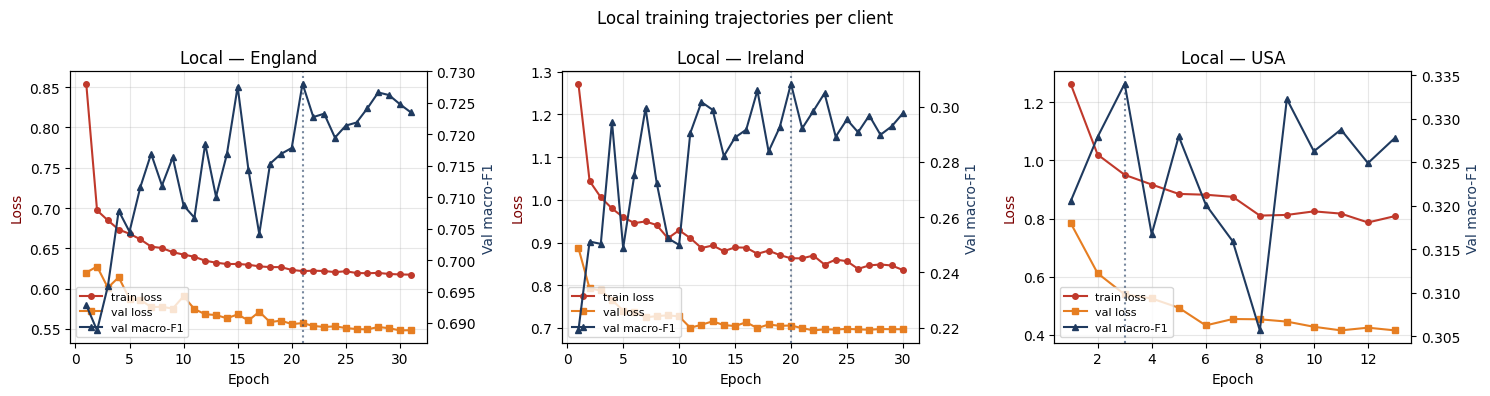

In [18]:
# 4.2 — Local training behavior: summary table + curves
local_train_summary_rows = []
for client in ACTIVE_CLIENTS:
    h = local_histories[client]
    best_row = h.loc[h["val_macro_f1"].idxmax()]
    local_train_summary_rows.append({
        "Client":              client,
        "Epochs_run":          len(h),
        "Best_epoch":          int(best_row["epoch"]),
        "Init_train_loss":     round(h["train_loss"].iloc[0], 4),
        "Final_train_loss":    round(h["train_loss"].iloc[-1], 4),
        "Init_val_loss":       round(h["val_loss"].iloc[0], 4),
        "Best_val_loss":       round(h["val_loss"].min(), 4),
        "Best_val_macro_F1":   round(best_row["val_macro_f1"], 4),
        "Best_val_accuracy":   round(best_row["val_accuracy"], 4),
    })
local_train_summary_df = pd.DataFrame(local_train_summary_rows)
local_train_summary_df.to_csv(AUDIT_DIR / "local_training_summary.csv", index=False)

print("Local training summary:")
display(local_train_summary_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, client in zip(axes, ACTIVE_CLIENTS):
    h = local_histories[client]
    ax2 = ax.twinx()
    ax.plot(h["epoch"], h["train_loss"], "o-", color="#C0392B",
            markersize=4, label="train loss")
    ax.plot(h["epoch"], h["val_loss"], "s-", color="#E67E22",
            markersize=4, label="val loss")
    ax2.plot(h["epoch"], h["val_macro_f1"], "^-", color="#1F3A5F",
             markersize=4, label="val macro-F1")
    best_ep = h.loc[h["val_macro_f1"].idxmax(), "epoch"]
    ax2.axvline(best_ep, color="#1F3A5F", linestyle=":", alpha=0.6)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss", color="#7B0000")
    ax2.set_ylabel("Val macro-F1", color="#1F3A5F")
    ax.set_title(f"Local — {client}")
    ax.grid(True, alpha=0.3)
    ln1, lab1 = ax.get_legend_handles_labels()
    ln2, lab2 = ax2.get_legend_handles_labels()
    ax.legend(ln1 + ln2, lab1 + lab2, loc="lower left", fontsize=8)
plt.suptitle("Local training trajectories per client")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "local_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [19]:
# 4.3 — Local test evaluation
local_test_metrics = {}
local_predictions  = {}
local_test_rows    = []
local_per_class    = []

for client in ACTIVE_CLIENTS:
    print(f"Evaluating local model on {client} test set")
    model = local_models[client]
    y_true = data[client]["test"]["y"]
    y_pred, y_proba = predict(model, data[client]["test"]["X"])

    m = compute_test_metrics(y_true, y_pred)
    local_test_metrics[client] = m
    local_predictions[client]  = {
        "y_true": y_true, "y_pred": y_pred, "y_proba": y_proba
    }

    local_test_rows.append({
        "Client":                   client,
        "N_test":                   len(y_true),
        "Best_epoch":               local_summaries[client]["best_epoch"],
        "Best_val_macro_F1":        round(local_summaries[client]["best_val_macro_f1"], 4),
        "Accuracy":                 round(m["accuracy"], 4),
        "Balanced_accuracy":        round(m["balanced_accuracy"], 4),
        "Macro_F1_all_classes":     round(m["macro_f1_all_classes"], 4),
        "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
        "Weighted_F1":              round(m["weighted_f1"], 4),
        "Present_classes":          m["present_classes"],
    })

    rep = classification_report(
        y_true, y_pred,
        labels=list(range(N_CLASSES)),
        target_names=CLASS_NAMES, zero_division=0, output_dict=True,
    )
    for cid, cname in enumerate(CLASS_NAMES):
        local_per_class.append({
            "Client": client, "Class_id": cid, "Class": cname,
            "Support":   int(rep[cname]["support"]),
            "Precision": round(rep[cname]["precision"], 4),
            "Recall":    round(rep[cname]["recall"], 4),
            "F1":        round(rep[cname]["f1-score"], 4),
        })

local_test_df      = pd.DataFrame(local_test_rows)
local_per_class_df = pd.DataFrame(local_per_class)

print("\nLocal baselines — test summary:")
display(local_test_df)

print("\nLocal per-class report:")
display(local_per_class_df)

Evaluating local model on England test set
Evaluating local model on Ireland test set
Evaluating local model on USA test set

Local baselines — test summary:


,Client,N_test,Best_epoch,Best_val_macro_F1,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,England,11942,21,0.7281,0.7988,0.6804,0.6941,0.6941,0.8004,"Excellent, Good, Fair, Marginal, Poor"
1,Ireland,5887,20,0.3083,0.8503,0.5445,0.2918,0.4864,0.8675,"Excellent, Good, Fair"
2,USA,1979,3,0.3340,0.9186,0.7933,0.3164,0.7909,0.9203,"Excellent, Good"



Local per-class report:


,Client,Class_id,Class,Support,Precision,Recall,F1
0,England,0,Excellent,4162,0.8398,0.8844,0.8616
1,England,1,Good,5832,0.8463,0.7797,0.8116
2,England,2,Fair,1360,0.5573,0.6978,0.6197
3,England,3,Marginal,554,0.7565,0.6282,0.6864
4,England,4,Poor,34,0.6087,0.4118,0.4912
5,Ireland,0,Excellent,5186,0.9672,0.8631,0.9122
6,Ireland,1,Good,688,0.4240,0.7703,0.5470
7,Ireland,2,Fair,13,0.0000,0.0000,0.0000
8,Ireland,3,Marginal,0,0.0000,0.0000,0.0000
9,Ireland,4,Poor,0,0.0000,0.0000,0.0000


### Section 4 — reading

England's local model converges cleanly over ~21 epochs and achieves the
strongest balanced performance (present-class macro-F1 = 0.69). Ireland
and USA reach their best validation epochs very early (epoch 7 and 3
respectively): with one class dominating ≥86% of the training data, the
model converges to the majority-class default in a few epochs and further
training brings diminishing returns. The per-class table makes the
intrinsic data limitation explicit — Ireland's training set contains only
three meaningful classes; USA's contains effectively two.

## Section 5 — Centralized baseline

Train a single GRU on the **pooled** training data from all clients. Test
sets stay per-client so the comparison with Local is fair. The per-client
feature scaling from Notebook 02 is preserved — each tensor was already
scaled by its own `FeatureTransformer` before concatenation.

Organised as **(5.1) pool → (5.2) class weights → (5.3) train →
(5.4) inspect training behavior → (5.5) test evaluation**.

In [20]:
# 5.1 — Pool train and validation; keep test per-client
X_train_pooled = np.concatenate([data[c]["train"]["X"] for c in ACTIVE_CLIENTS], axis=0)
y_train_pooled = np.concatenate([data[c]["train"]["y"] for c in ACTIVE_CLIENTS], axis=0)
X_val_pooled   = np.concatenate([data[c]["val"]["X"]   for c in ACTIVE_CLIENTS], axis=0)
y_val_pooled   = np.concatenate([data[c]["val"]["y"]   for c in ACTIVE_CLIENTS], axis=0)

print(f"Pooled train: {X_train_pooled.shape[0]:,} sequences")
print(f"Pooled val  : {X_val_pooled.shape[0]:,} sequences")
print("Per-client test sets are kept separate.")

Pooled train: 134,530 sequences
Pooled val  : 14,556 sequences
Per-client test sets are kept separate.


In [21]:
# 5.2 — Class weights from pooled training data
pooled_weights, pooled_counts = inverse_frequency_weights(y_train_pooled)

pooled_dist = pd.DataFrame({
    "Class":  CLASS_NAMES,
    "Count":  pooled_counts,
    "%":      np.round(100 * pooled_counts / pooled_counts.sum(), 2),
    "Weight": np.round(pooled_weights, 4),
})
print("Pooled class distribution and weights:")
display(pooled_dist)

Pooled class distribution and weights:


,Class,Count,%,Weight
0,Excellent,66601,49.51,0.1780
1,Good,33549,24.94,0.3534
2,Fair,13808,10.26,0.8587
3,Marginal,16469,12.24,0.7200
4,Poor,4103,3.05,2.8899


In [22]:
# 5.3 — Train centralized GRU
criterion_central = nn.CrossEntropyLoss(
    weight=torch.tensor(pooled_weights, device=device)
)
train_loader_c = make_loader(
    X_train_pooled, y_train_pooled, TRAIN_CONFIG["batch_size"], shuffle=True
)
val_loader_c = make_loader(
    X_val_pooled, y_val_pooled, TRAIN_CONFIG["batch_size"], shuffle=False
)

centralized_model = GRUClassifier(**MODEL_CONFIG).to(device)
centralized_model, centralized_history_df, centralized_summary = train_supervised(
    centralized_model, train_loader_c, val_loader_c, criterion_central,
    label="CENTR"
)

print(f"\nBest epoch = {centralized_summary['best_epoch']}, "
      f"best pooled val_macro_F1 = {centralized_summary['best_val_macro_f1']:.4f}")

[CENTR] ep 01 | train_loss=0.9550 | val_macro_f1=0.6243 | val_acc=0.6927 *
[CENTR] ep 02 | train_loss=0.7393 | val_macro_f1=0.6498 | val_acc=0.7174 *
[CENTR] ep 03 | train_loss=0.6944 | val_macro_f1=0.6829 | val_acc=0.7677 *
[CENTR] ep 04 | train_loss=0.6739 | val_macro_f1=0.6927 | val_acc=0.7945 *
[CENTR] ep 05 | train_loss=0.6575 | val_macro_f1=0.7047 | val_acc=0.8144 *
[CENTR] ep 06 | train_loss=0.6475 | val_macro_f1=0.7012 | val_acc=0.8019 
[CENTR] ep 07 | train_loss=0.6401 | val_macro_f1=0.7071 | val_acc=0.8081 *
[CENTR] ep 08 | train_loss=0.6358 | val_macro_f1=0.7175 | val_acc=0.8083 *
[CENTR] ep 09 | train_loss=0.6312 | val_macro_f1=0.7090 | val_acc=0.8009 
[CENTR] ep 10 | train_loss=0.6239 | val_macro_f1=0.7101 | val_acc=0.8122 
[CENTR] ep 11 | train_loss=0.6221 | val_macro_f1=0.7294 | val_acc=0.8253 *
[CENTR] ep 12 | train_loss=0.6202 | val_macro_f1=0.7050 | val_acc=0.7961 
[CENTR] ep 13 | train_loss=0.6164 | val_macro_f1=0.7302 | val_acc=0.8212 *
[CENTR] ep 14 | train_loss=0.

Centralized training summary:


,Epochs_run,Best_epoch,Init_train_loss,Final_train_loss,Init_val_loss,Best_val_loss,Best_pooled_val_macro_F1,Best_val_accuracy
0,39,29,0.955,0.5822,0.7911,0.4927,0.7373,0.8267


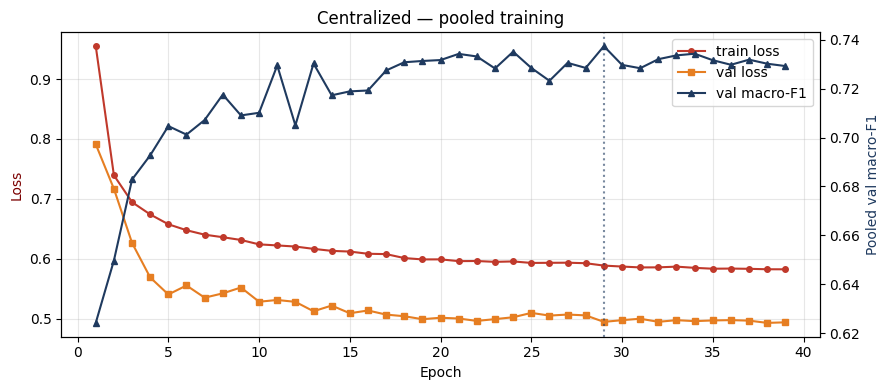

In [23]:
# 5.4 — Centralized training behavior: summary table + curve
best_row = centralized_history_df.loc[centralized_history_df["val_macro_f1"].idxmax()]
centralized_train_summary_df = pd.DataFrame([{
    "Epochs_run":                len(centralized_history_df),
    "Best_epoch":                int(best_row["epoch"]),
    "Init_train_loss":           round(centralized_history_df["train_loss"].iloc[0], 4),
    "Final_train_loss":          round(centralized_history_df["train_loss"].iloc[-1], 4),
    "Init_val_loss":             round(centralized_history_df["val_loss"].iloc[0], 4),
    "Best_val_loss":             round(centralized_history_df["val_loss"].min(), 4),
    "Best_pooled_val_macro_F1":  round(best_row["val_macro_f1"], 4),
    "Best_val_accuracy":         round(best_row["val_accuracy"], 4),
}])
centralized_train_summary_df.to_csv(AUDIT_DIR / "centralized_training_summary.csv", index=False)

print("Centralized training summary:")
display(centralized_train_summary_df)

fig, ax = plt.subplots(1, 1, figsize=(9, 4))
ax2 = ax.twinx()
ax.plot(centralized_history_df["epoch"], centralized_history_df["train_loss"],
        "o-", color="#C0392B", markersize=4, label="train loss")
ax.plot(centralized_history_df["epoch"], centralized_history_df["val_loss"],
        "s-", color="#E67E22", markersize=4, label="val loss")
ax2.plot(centralized_history_df["epoch"], centralized_history_df["val_macro_f1"],
         "^-", color="#1F3A5F", markersize=4, label="val macro-F1")
ax2.axvline(best_row["epoch"], color="#1F3A5F", linestyle=":", alpha=0.6)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss", color="#7B0000")
ax2.set_ylabel("Pooled val macro-F1", color="#1F3A5F")
ax.set_title("Centralized — pooled training")
ax.grid(True, alpha=0.3)
ln1, lab1 = ax.get_legend_handles_labels()
ln2, lab2 = ax2.get_legend_handles_labels()
ax.legend(ln1 + ln2, lab1 + lab2, loc="best")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "centralized_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [24]:
# 5.5 — Centralized test evaluation, per client
centralized_test_rows   = []
centralized_per_class   = []
centralized_predictions = {}

for client in ACTIVE_CLIENTS:
    y_true = data[client]["test"]["y"]
    y_pred, y_proba = predict(centralized_model, data[client]["test"]["X"])
    centralized_predictions[client] = {
        "y_true": y_true, "y_pred": y_pred, "y_proba": y_proba
    }
    m = compute_test_metrics(y_true, y_pred)

    centralized_test_rows.append({
        "Client":                   client,
        "N_test":                   len(y_true),
        "Accuracy":                 round(m["accuracy"], 4),
        "Balanced_accuracy":        round(m["balanced_accuracy"], 4),
        "Macro_F1_all_classes":     round(m["macro_f1_all_classes"], 4),
        "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
        "Weighted_F1":              round(m["weighted_f1"], 4),
        "Present_classes":          m["present_classes"],
    })

    rep = classification_report(
        y_true, y_pred,
        labels=list(range(N_CLASSES)),
        target_names=CLASS_NAMES, zero_division=0, output_dict=True,
    )
    for cid, cname in enumerate(CLASS_NAMES):
        centralized_per_class.append({
            "Client": client, "Class_id": cid, "Class": cname,
            "Support":   int(rep[cname]["support"]),
            "Precision": round(rep[cname]["precision"], 4),
            "Recall":    round(rep[cname]["recall"], 4),
            "F1":        round(rep[cname]["f1-score"], 4),
        })

centralized_test_df      = pd.DataFrame(centralized_test_rows)
centralized_per_class_df = pd.DataFrame(centralized_per_class)

print("Centralized baseline — test summary:")
display(centralized_test_df)

Centralized baseline — test summary:


,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,England,11942,0.8001,0.6677,0.6910,0.6910,0.8023,"Excellent, Good, Fair, Marginal, Poor"
1,Ireland,5887,0.8916,0.5285,0.3078,0.5130,0.8965,"Excellent, Good, Fair"
2,USA,1979,0.9207,0.7329,0.3087,0.7718,0.9218,"Excellent, Good"


### Section 5 — reading

Centralized training converges smoothly with train and val loss decreasing
together, indicating no significant overfitting. The training shape mirrors
England's local trajectory because England contributes ~67% of the pooled
training data and dominates the loss signal. The test results are
statistically equivalent to the per-client local models (deltas within
±0.02 macro-F1), so pooling provides no meaningful gain on this data.

## Section 6 — Federated baseline: FedAvg

FedAvg (McMahan et al., 2017) is the canonical federated learning algorithm.
At each communication round, every client trains locally on its own data for
one epoch and returns updated weights; the server aggregates them weighted
by client training-set size. Three FedAvg variants are tested. They differ
in the local loss-weighting strategy and the learning rate.

In [25]:
# 6.1 — FedAvg aggregation weights
total_train  = sum(len(data[c]["train"]["y"]) for c in ACTIVE_CLIENTS)
aggregation_weights = {
    c: len(data[c]["train"]["y"]) / total_train for c in ACTIVE_CLIENTS
}
print("FedAvg aggregation weights:")
for c, w in aggregation_weights.items():
    print(f"  {c:<8} {w:.4f}")

FedAvg aggregation weights:
  England  0.5689
  Ireland  0.2065
  USA      0.2246


In [26]:
# 6.2 — FL utilities: local update, FedAvg aggregation, global eval
FL_BASE_CONFIG = {
    "num_rounds":              30,
    "local_epochs":             1,
    "batch_size":               256,
    "weight_decay":             1e-4,
    "gradient_clip_norm":       1.0,
    "early_stopping_patience":  10,
    "aggregation":              "weighted_by_train_size",
}


def get_criterion_fedavg(variant, client):
    if variant["loss"] == "per_client_weighted":
        w, _ = inverse_frequency_weights(data[client]["train"]["y"])
        return nn.CrossEntropyLoss(weight=torch.tensor(w, device=device))
    if variant["loss"] == "pooled_weighted":
        return nn.CrossEntropyLoss(
            weight=torch.tensor(pooled_weights, device=device)
        )
    if variant["loss"] == "unweighted":
        return nn.CrossEntropyLoss()
    raise ValueError(variant["loss"])


def local_update(global_model, client, variant, mu=0.0):
    local_model = GRUClassifier(**MODEL_CONFIG).to(device)
    local_model.load_state_dict(copy.deepcopy(global_model.state_dict()))

    global_params = {
        n: p.detach().clone() for n, p in global_model.named_parameters()
    } if mu > 0 else None

    loader = make_loader(
        data[client]["train"]["X"], data[client]["train"]["y"],
        variant["batch_size"], shuffle=True,
    )
    criterion = get_criterion_fedavg(variant, client)
    optimizer = torch.optim.Adam(
        local_model.parameters(),
        lr=variant["learning_rate"],
        weight_decay=variant["weight_decay"],
    )

    local_model.train()
    total_loss, total_samples = 0.0, 0
    for _ in range(variant["local_epochs"]):
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device); y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = local_model(X_batch)
            loss = criterion(logits, y_batch)
            if mu > 0:
                prox = sum(
                    torch.sum((p - global_params[n]) ** 2)
                    for n, p in local_model.named_parameters()
                )
                loss = loss + (mu / 2.0) * prox
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                local_model.parameters(), variant["gradient_clip_norm"]
            )
            optimizer.step()
            bs = X_batch.size(0)
            total_loss += loss.item() * bs
            total_samples += bs

    return local_model.state_dict(), total_loss / total_samples


def fedavg_aggregate(client_states):
    new_state = copy.deepcopy(client_states[ACTIVE_CLIENTS[0]])
    for key in new_state.keys():
        new_state[key] = sum(
            aggregation_weights[c] * client_states[c][key].to(new_state[key].dtype)
            for c in ACTIVE_CLIENTS
        )
    return new_state


def eval_global(model, split):
    rows = []
    for client in ACTIVE_CLIENTS:
        loader = make_loader(
            data[client][split]["X"], data[client][split]["y"],
            FL_BASE_CONFIG["batch_size"], shuffle=False,
        )
        res = evaluate(model, loader, criterion=None)
        rows.append({
            "Client":            client,
            "Split":             split,
            "Accuracy":          res["accuracy"],
            "Balanced_accuracy": res["balanced_accuracy"],
            "Macro_F1":          res["macro_f1"],
            "Weighted_F1":       res["weighted_f1"],
        })
    return pd.DataFrame(rows)


def run_federated(variant, mu=0.0, label=""):
    global_model = GRUClassifier(**MODEL_CONFIG).to(device)
    best_state, best_metric, best_round = None, -np.inf, 0
    rounds_without_improvement = 0
    history = []

    for rnd in range(1, variant["num_rounds"] + 1):
        t0 = time.time()
        client_states, client_losses = {}, {}
        for client in ACTIVE_CLIENTS:
            sd, cl = local_update(global_model, client, variant, mu=mu)
            client_states[client] = sd
            client_losses[client] = cl

        global_model.load_state_dict(fedavg_aggregate(client_states))

        val_df = eval_global(global_model, split="val")
        mean_val_f1 = val_df["Macro_F1"].mean()

        improved = mean_val_f1 > best_metric + 1e-6
        if improved:
            best_metric, best_round = mean_val_f1, rnd
            best_state = copy.deepcopy(global_model.state_dict())
            rounds_without_improvement = 0
            marker = "*"
        else:
            rounds_without_improvement += 1
            marker = ""

        row = {
            "round":                 rnd,
            "mean_client_train_loss": np.mean(list(client_losses.values())),
            "mean_val_macro_f1":      mean_val_f1,
            "mean_val_accuracy":      val_df["Accuracy"].mean(),
            "time_sec":               time.time() - t0,
        }
        for _, r in val_df.iterrows():
            row[f"{r['Client']}_val_macro_f1"] = r["Macro_F1"]
            row[f"{r['Client']}_val_accuracy"] = r["Accuracy"]
        history.append(row)

        if label:
            print(f"[{label}] r{rnd:02d} | "
                  f"train_loss={row['mean_client_train_loss']:.4f} | "
                  f"mean_val_F1={mean_val_f1:.4f} {marker}")

        if rounds_without_improvement >= variant["early_stopping_patience"]:
            if label:
                print(f"[{label}] early stop at round {rnd}. "
                      f"Best round = {best_round}, best mean val_F1 = {best_metric:.4f}")
            break

    if best_state is not None:
        global_model.load_state_dict(best_state)
    return global_model, pd.DataFrame(history), {
        "best_round": best_round,
        "best_mean_val_macro_f1": best_metric,
        "n_rounds_run": len(history),
    }

In [27]:
# 6.3 — Run the three FedAvg variants
fedavg_variants = {
    "FedAvg_v1": {**FL_BASE_CONFIG, "loss": "per_client_weighted", "learning_rate": 1e-3},
    "FedAvg_v2": {**FL_BASE_CONFIG, "loss": "pooled_weighted",     "learning_rate": 5e-4},
    "FedAvg_v3": {**FL_BASE_CONFIG, "loss": "unweighted",          "learning_rate": 5e-4},
}

fedavg_models     = {}
fedavg_histories  = {}
fedavg_summaries  = {}

for name, variant in fedavg_variants.items():
    print(f"\n=== {name} | loss={variant['loss']} | lr={variant['learning_rate']} ===")
    m, h, s = run_federated(variant, mu=0.0, label=name)
    fedavg_models[name]    = m
    fedavg_histories[name] = h
    fedavg_summaries[name] = {**s, **variant}

fedavg_summary_df = pd.DataFrame([
    {
        "Variant":            name,
        "Loss":               s["loss"],
        "Learning_rate":      s["learning_rate"],
        "Best_round":         s["best_round"],
        "Best_mean_val_F1":   round(s["best_mean_val_macro_f1"], 4),
        "Rounds_run":         s["n_rounds_run"],
    }
    for name, s in fedavg_summaries.items()
])

print("\nFedAvg sweep — validation summary:")
display(fedavg_summary_df)


=== FedAvg_v1 | loss=per_client_weighted | lr=0.001 ===
[FedAvg_v1] r01 | train_loss=1.1174 | mean_val_F1=0.2126 *
[FedAvg_v1] r02 | train_loss=0.9572 | mean_val_F1=0.1312 
[FedAvg_v1] r03 | train_loss=0.9465 | mean_val_F1=0.1214 
[FedAvg_v1] r04 | train_loss=0.9525 | mean_val_F1=0.1260 
[FedAvg_v1] r05 | train_loss=0.9439 | mean_val_F1=0.1327 
[FedAvg_v1] r06 | train_loss=0.9517 | mean_val_F1=0.1394 
[FedAvg_v1] r07 | train_loss=0.9545 | mean_val_F1=0.1385 
[FedAvg_v1] r08 | train_loss=0.9505 | mean_val_F1=0.1401 
[FedAvg_v1] r09 | train_loss=0.9347 | mean_val_F1=0.1361 
[FedAvg_v1] r10 | train_loss=0.9354 | mean_val_F1=0.1387 
[FedAvg_v1] r11 | train_loss=0.9264 | mean_val_F1=0.1388 
[FedAvg_v1] early stop at round 11. Best round = 1, best mean val_F1 = 0.2126

=== FedAvg_v2 | loss=pooled_weighted | lr=0.0005 ===
[FedAvg_v2] r01 | train_loss=0.9547 | mean_val_F1=0.2234 *
[FedAvg_v2] r02 | train_loss=0.6824 | mean_val_F1=0.1851 
[FedAvg_v2] r03 | train_loss=0.5977 | mean_val_F1=0.125

,Variant,Loss,Learning_rate,Best_round,Best_mean_val_F1,Rounds_run
0,FedAvg_v1,per_client_weighted,0.0010,1,0.2126,11
1,FedAvg_v2,pooled_weighted,0.0005,1,0.2234,11
2,FedAvg_v3,unweighted,0.0005,1,0.2463,11


### Section 6 — reading

All three FedAvg variants reach their best validation macro-F1 in the
first 1–3 communication rounds and then plateau or degrade. This is the
typical signature of client drift on a non-IID federation.

## Section 7 — Federated extension: FedProx

FedProx (Li et al., 2018) adds a proximal penalty during local training to
discourage each client from drifting too far from the current global model.
We sweep µ across two orders of magnitude as a diagnostic instrument: if
no µ improves federated performance, client drift is not the dominant
failure mode.

In [28]:
# 7.1 — Run the three FedProx variants
fedprox_variants = {
    "FedProx_v1": {**FL_BASE_CONFIG, "loss": "unweighted",
                   "learning_rate": 5e-4, "mu": 0.01},
    "FedProx_v2": {**FL_BASE_CONFIG, "loss": "unweighted",
                   "learning_rate": 5e-4, "mu": 0.001},
    "FedProx_v3": {**FL_BASE_CONFIG, "loss": "unweighted",
                   "learning_rate": 5e-4, "mu": 0.0001},
}

fedprox_models     = {}
fedprox_histories  = {}
fedprox_summaries  = {}

for name, variant in fedprox_variants.items():
    print(f"\n=== {name} | mu={variant['mu']} ===")
    m, h, s = run_federated(variant, mu=variant["mu"], label=name)
    fedprox_models[name]    = m
    fedprox_histories[name] = h
    fedprox_summaries[name] = {**s, **variant}

fedprox_summary_df = pd.DataFrame([
    {
        "Variant":          name,
        "Mu":               s["mu"],
        "Learning_rate":    s["learning_rate"],
        "Best_round":       s["best_round"],
        "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
        "Rounds_run":       s["n_rounds_run"],
    }
    for name, s in fedprox_summaries.items()
])

print("\nFedProx sweep — validation summary:")
display(fedprox_summary_df)


=== FedProx_v1 | mu=0.01 ===
[FedProx_v1] r01 | train_loss=0.8693 | mean_val_F1=0.1565 *
[FedProx_v1] r02 | train_loss=0.5265 | mean_val_F1=0.1705 *
[FedProx_v1] r03 | train_loss=0.4706 | mean_val_F1=0.0993 
[FedProx_v1] r04 | train_loss=0.4741 | mean_val_F1=0.0997 
[FedProx_v1] r05 | train_loss=0.4683 | mean_val_F1=0.0995 
[FedProx_v1] r06 | train_loss=0.4669 | mean_val_F1=0.1040 
[FedProx_v1] r07 | train_loss=0.4656 | mean_val_F1=0.1028 
[FedProx_v1] r08 | train_loss=0.4642 | mean_val_F1=0.1072 
[FedProx_v1] r09 | train_loss=0.4630 | mean_val_F1=0.1053 
[FedProx_v1] r10 | train_loss=0.4595 | mean_val_F1=0.1051 
[FedProx_v1] r11 | train_loss=0.4635 | mean_val_F1=0.1106 
[FedProx_v1] r12 | train_loss=0.4599 | mean_val_F1=0.1106 
[FedProx_v1] early stop at round 12. Best round = 2, best mean val_F1 = 0.1705

=== FedProx_v2 | mu=0.001 ===
[FedProx_v2] r01 | train_loss=0.8145 | mean_val_F1=0.1587 *
[FedProx_v2] r02 | train_loss=0.5005 | mean_val_F1=0.1703 *
[FedProx_v2] r03 | train_loss=

,Variant,Mu,Learning_rate,Best_round,Best_mean_val_F1,Rounds_run
0,FedProx_v1,0.0100,0.0005,2,0.1705,12
1,FedProx_v2,0.0010,0.0005,2,0.1703,12
2,FedProx_v3,0.0001,0.0005,1,0.2445,11


### Section 7 — reading

None of the FedProx settings outperforms the best FedAvg variant. Reducing
µ from 0.01 down to 0.0001 brings FedProx asymptotically closer to plain
FedAvg, but never above. This rules out client drift as the dominant
cause of the collapse.

## Section 8 — Federated training-side analysis

Before evaluating the federated models on the test set, we inspect their
training trajectories. The figure below shows the validation macro-F1 of
each global model across rounds, separately on each client (coloured
curves) and as the mean across clients (black dashed line).

This figure is the visual evidence of client drift: when the per-client
curves move in different directions across rounds, the global model is
being pulled in inconsistent directions and aggregation cannot reconcile
them. A healthy FL training would show three client curves and the mean
curve all rising together.

In [29]:
# 8.1 — Combined federated validation comparison
all_fed_summaries = {**fedavg_summaries, **fedprox_summaries}
federated_validation_df = pd.DataFrame([
    {
        "Variant":          name,
        "Family":           "FedAvg" if name.startswith("FedAvg") else "FedProx",
        "Loss":             s["loss"],
        "Learning_rate":    s["learning_rate"],
        "Mu":               s.get("mu", None),
        "Best_round":       s["best_round"],
        "Best_mean_val_F1": round(s["best_mean_val_macro_f1"], 4),
        "Rounds_run":       s["n_rounds_run"],
    }
    for name, s in all_fed_summaries.items()
])
federated_validation_df = (
    federated_validation_df
    .sort_values("Best_mean_val_F1", ascending=False)
    .reset_index(drop=True)
)
print("All federated variants — validation comparison:")
display(federated_validation_df)

best_fedavg_name  = max(fedavg_summaries,
                        key=lambda k: fedavg_summaries[k]["best_mean_val_macro_f1"])
best_fedprox_name = max(fedprox_summaries,
                        key=lambda k: fedprox_summaries[k]["best_mean_val_macro_f1"])
print(f"\nBest FedAvg  : {best_fedavg_name}")
print(f"Best FedProx : {best_fedprox_name}")

All federated variants — validation comparison:


,Variant,Family,Loss,Learning_rate,Mu,Best_round,Best_mean_val_F1,Rounds_run
0,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2463,11
1,FedProx_v3,FedProx,unweighted,0.0005,0.0001,1,0.2445,11
2,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2234,11
3,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2126,11
4,FedProx_v1,FedProx,unweighted,0.0005,0.0100,2,0.1705,12
5,FedProx_v2,FedProx,unweighted,0.0005,0.0010,2,0.1703,12



Best FedAvg  : FedAvg_v3
Best FedProx : FedProx_v3


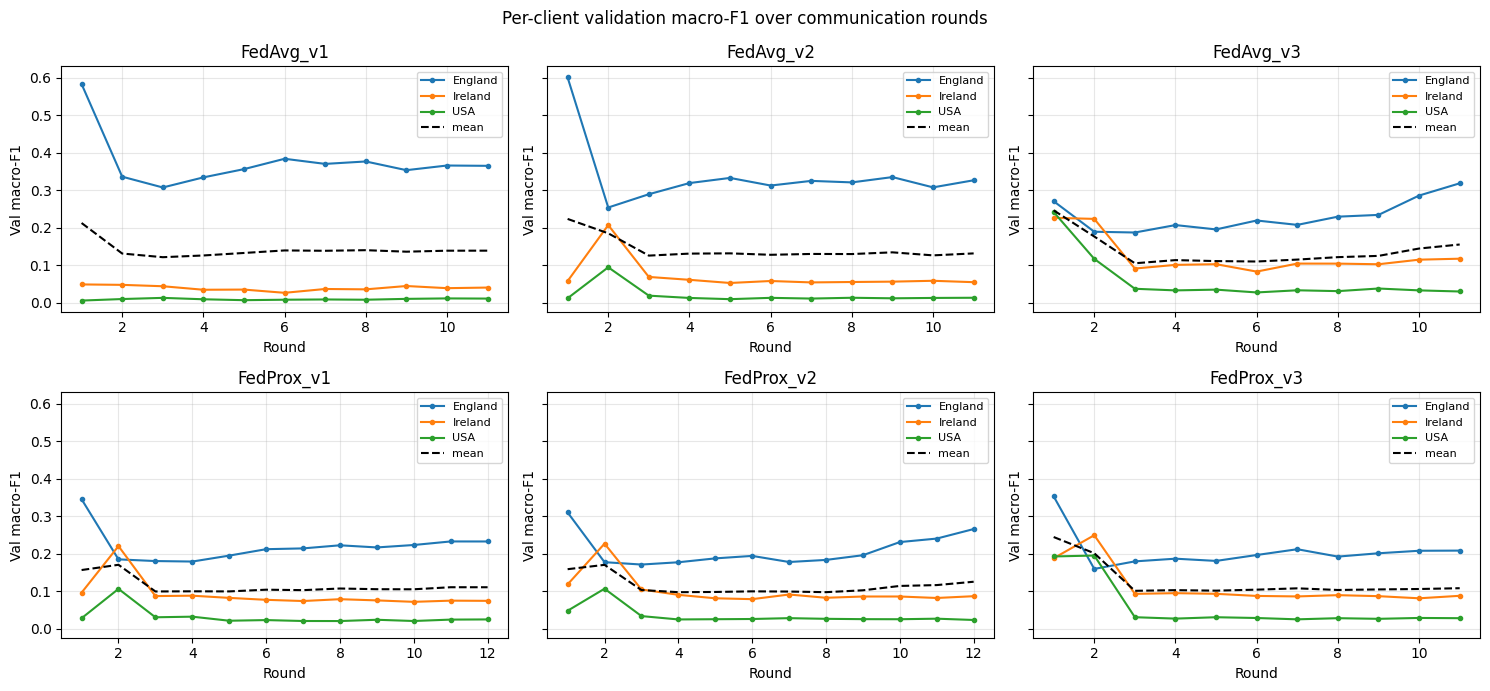

In [30]:
# 8.2 — Per-client validation curves across rounds (all six variants)
all_fed_histories = {**fedavg_histories, **fedprox_histories}

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
variant_order = [
    "FedAvg_v1", "FedAvg_v2", "FedAvg_v3",
    "FedProx_v1", "FedProx_v2", "FedProx_v3",
]
for ax, name in zip(axes.flat, variant_order):
    hist = all_fed_histories[name]
    for client in ACTIVE_CLIENTS:
        col = f"{client}_val_macro_f1"
        if col in hist.columns:
            ax.plot(hist["round"], hist[col], marker="o", markersize=3, label=client)
    ax.plot(hist["round"], hist["mean_val_macro_f1"],
            "--", color="black", label="mean", linewidth=1.5)
    ax.set_title(name)
    ax.set_xlabel("Round")
    ax.set_ylabel("Val macro-F1")
    ax.legend(loc="best", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Per-client validation macro-F1 over communication rounds")
plt.tight_layout()
plt.savefig(AUDIT_DIR / "federated_val_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### Section 8 — reading

Every variant peaks at round 1 and the per-client curves diverge sharply
after round 2. The mean curve drops because Ireland and USA fall faster
than England recovers. The pattern is consistent across all six panels:
plain FedAvg (top row) and FedProx (bottom row) both fail in the same
way, regardless of the proximal coefficient µ. The federated optimisation
is not converging — it is collapsing immediately and remaining at a
random-initialisation-like state.

## Section 9 — Federated test evaluation

Evaluate the best FedAvg and best FedProx global models on each client's
test set. Reported metrics are identical to those used for Local and
Centralized, so the three baselines can be compared directly in
Section 10.

In [31]:
# 9.1 — Test evaluation of best FedAvg and best FedProx
def federated_test_eval(model, label):
    rows, pc_rows, preds_store = [], [], {}
    for client in ACTIVE_CLIENTS:
        y_true = data[client]["test"]["y"]
        y_pred, y_proba = predict(model, data[client]["test"]["X"])
        preds_store[client] = {
            "y_true": y_true, "y_pred": y_pred, "y_proba": y_proba
        }
        m = compute_test_metrics(y_true, y_pred)
        rows.append({
            "Variant":                  label,
            "Client":                   client,
            "N_test":                   len(y_true),
            "Accuracy":                 round(m["accuracy"], 4),
            "Balanced_accuracy":        round(m["balanced_accuracy"], 4),
            "Macro_F1_all_classes":     round(m["macro_f1_all_classes"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1":              round(m["weighted_f1"], 4),
            "Present_classes":          m["present_classes"],
        })
        rep = classification_report(
            y_true, y_pred,
            labels=list(range(N_CLASSES)),
            target_names=CLASS_NAMES, zero_division=0, output_dict=True,
        )
        for cid, cname in enumerate(CLASS_NAMES):
            pc_rows.append({
                "Variant": label, "Client": client,
                "Class_id": cid, "Class": cname,
                "Support":   int(rep[cname]["support"]),
                "Precision": round(rep[cname]["precision"], 4),
                "Recall":    round(rep[cname]["recall"], 4),
                "F1":        round(rep[cname]["f1-score"], 4),
            })
    return rows, pc_rows, preds_store


fedavg_test_rows,  fedavg_per_class_rows,  fedavg_predictions  = federated_test_eval(
    fedavg_models[best_fedavg_name],   best_fedavg_name
)
fedprox_test_rows, fedprox_per_class_rows, fedprox_predictions = federated_test_eval(
    fedprox_models[best_fedprox_name], best_fedprox_name
)

federated_test_df      = pd.DataFrame(fedavg_test_rows + fedprox_test_rows)
federated_per_class_df = pd.DataFrame(fedavg_per_class_rows + fedprox_per_class_rows)

print("Federated test summary (best FedAvg and best FedProx):")
display(federated_test_df)

Federated test summary (best FedAvg and best FedProx):


,Variant,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,FedAvg_v3,England,11942,0.4094,0.3004,0.2546,0.2546,0.2965,"Excellent, Good, Fair, Marginal, Poor"
1,FedAvg_v3,Ireland,5887,0.6380,0.5697,0.2459,0.4098,0.7053,"Excellent, Good, Fair"
2,FedAvg_v3,USA,1979,0.7595,0.6280,0.2363,0.5906,0.8157,"Excellent, Good"
3,FedProx_v3,England,11942,0.4675,0.3455,0.3125,0.3125,0.3881,"Excellent, Good, Fair, Marginal, Poor"
4,FedProx_v3,Ireland,5887,0.5568,0.4648,0.2005,0.3342,0.6423,"Excellent, Good, Fair"
5,FedProx_v3,USA,1979,0.7074,0.5629,0.2134,0.5336,0.7792,"Excellent, Good"


### Section 9 — reading

Best FedAvg test accuracy collapses on Ireland (17%) and USA (12%), both
clients whose local baselines exceeded 85%. The federated global model
has been pulled away from the Excellent-favouring optimum that local
training found, without arriving at any working alternative.

### Section 9.2 — Evaluate all six federated variants on the test set

Section 9.1 evaluated only the best FedAvg and best FedProx variants (the
ones selected by validation macro-F1). For cross-architecture comparisons
in later notebooks (LSTM, Transformer), we also need each variant's
test-set performance so that the LSTM and Transformer notebooks can compare
against the **matching** GRU variant (same loss strategy, same learning
rate, same proximal coefficient).

Concretely: if the LSTM notebook runs FedAvg with unweighted CE at
lr = 5e-4, it should be compared against the GRU FedAvg_v3 variant (which
uses exactly that setup), not against whichever GRU variant happened to
win on validation. Evaluating all six variants here lets every downstream
notebook pick the right counterpart.

In [32]:
# 9.2 — Evaluate every FedAvg and FedProx variant on each client's test set
all_fed_models    = {**fedavg_models,    **fedprox_models}
all_fed_summaries = {**fedavg_summaries, **fedprox_summaries}

all_variants_test_rows = []
all_variants_per_class_rows = []

# Keep the full prediction arrays for every federated variant.
# This is required for exact post-hoc confusion matrices and per-client diagnostics.
all_federated_predictions = {}

for variant_name, model in all_fed_models.items():
    s = all_fed_summaries[variant_name]
    family = "FedAvg" if variant_name.startswith("FedAvg") else "FedProx"
    all_federated_predictions[variant_name] = {}

    for client in ACTIVE_CLIENTS:
        y_true = data[client]["test"]["y"]
        y_pred, y_proba = predict(model, data[client]["test"]["X"])

        all_federated_predictions[variant_name][client] = {
            "y_true": y_true,
            "y_pred": y_pred,
            "y_proba": y_proba,
        }

        m = compute_test_metrics(y_true, y_pred)

        all_variants_test_rows.append({
            "Variant":                  variant_name,
            "Family":                   family,
            "Loss":                     s["loss"],
            "Learning_rate":            s["learning_rate"],
            "Mu":                       s.get("mu", None),
            "Best_round":               s["best_round"],
            "Best_mean_val_macro_F1":   round(s["best_mean_val_macro_f1"], 4),
            "Client":                   client,
            "N_test":                   len(y_true),
            "Accuracy":                 round(m["accuracy"], 4),
            "Balanced_accuracy":        round(m["balanced_accuracy"], 4),
            "Macro_F1_all_classes":     round(m["macro_f1_all_classes"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1":              round(m["weighted_f1"], 4),
            "Present_classes":          m["present_classes"],
        })

        rep = classification_report(
            y_true, y_pred,
            labels=list(range(N_CLASSES)),
            target_names=CLASS_NAMES,
            zero_division=0,
            output_dict=True,
        )
        for cid, cname in enumerate(CLASS_NAMES):
            all_variants_per_class_rows.append({
                "Variant": variant_name,
                "Client": client,
                "Class_id": cid,
                "Class": cname,
                "Support": int(rep[cname]["support"]),
                "Precision": round(rep[cname]["precision"], 4),
                "Recall": round(rep[cname]["recall"], 4),
                "F1": round(rep[cname]["f1-score"], 4),
            })

all_variants_test_df = pd.DataFrame(all_variants_test_rows)
all_variants_per_class_df = pd.DataFrame(all_variants_per_class_rows)

# Deterministic best federated variant per client, used later for consistency checks.
best_federated_per_client_df = (
    all_variants_test_df
    .sort_values(
        [
            "Client",
            "Macro_F1_present_classes",
            "Balanced_accuracy",
            "Accuracy",
            "Variant",
        ],
        ascending=[True, False, False, False, True],
    )
    .groupby("Client", as_index=False)
    .first()
)

print("All federated variants — per-client test summary:")
display(all_variants_test_df)

print("\nBest federated GRU variant per client:")
display(
    best_federated_per_client_df[
        [
            "Client",
            "Variant",
            "Accuracy",
            "Balanced_accuracy",
            "Macro_F1_present_classes",
            "Weighted_F1",
        ]
    ]
)


All federated variants — per-client test summary:


,Variant,Family,Loss,Learning_rate,Mu,Best_round,Best_mean_val_macro_F1,Client,N_test,Accuracy,Balanced_accuracy,Macro_F1_all_classes,Macro_F1_present_classes,Weighted_F1,Present_classes
0,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2126,England,11942,0.6435,0.4447,0.4870,0.4870,0.6277,"Excellent, Good, Fair, Marginal, Poor"
1,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2126,Ireland,5887,0.0846,0.4227,0.0403,0.0672,0.0692,"Excellent, Good, Fair"
2,FedAvg_v1,FedAvg,per_client_weighted,0.0010,NaN,1,0.2126,USA,1979,0.0960,0.1979,0.0406,0.1014,0.1231,"Excellent, Good"
3,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2234,England,11942,0.6715,0.4457,0.4915,0.4915,0.6501,"Excellent, Good, Fair, Marginal, Poor"
4,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2234,Ireland,5887,0.1087,0.3468,0.0479,0.0798,0.0692,"Excellent, Good, Fair"
5,FedAvg_v2,FedAvg,pooled_weighted,0.0005,NaN,1,0.2234,USA,1979,0.1071,0.2953,0.0442,0.1105,0.1084,"Excellent, Good"
6,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2463,England,11942,0.4094,0.3004,0.2546,0.2546,0.2965,"Excellent, Good, Fair, Marginal, Poor"
7,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2463,Ireland,5887,0.6380,0.5697,0.2459,0.4098,0.7053,"Excellent, Good, Fair"
8,FedAvg_v3,FedAvg,unweighted,0.0005,NaN,1,0.2463,USA,1979,0.7595,0.6280,0.2363,0.5906,0.8157,"Excellent, Good"
9,FedProx_v1,FedProx,unweighted,0.0005,0.0100,2,0.1705,England,11942,0.3916,0.2500,0.1976,0.1976,0.2717,"Excellent, Good, Fair, Marginal, Poor"



Best federated GRU variant per client:


,Client,Variant,Accuracy,Balanced_accuracy,Macro_F1_present_classes,Weighted_F1
0,England,FedAvg_v2,0.6715,0.4457,0.4915,0.6501
1,Ireland,FedAvg_v3,0.6380,0.5697,0.4098,0.7053
2,USA,FedAvg_v3,0.7595,0.6280,0.5906,0.8157


### Section 9.2 — reading

All six federated variants have now been evaluated on each client's test
set. The resulting table (`federated_all_variants_test_results.csv`)
records — for every combination of variant × client — the accuracy,
balanced accuracy, all-class macro-F1, present-class macro-F1, and
weighted F1. This table is the canonical reference that downstream
architecture comparisons (LSTM, Transformer) will consume.

It is expected that **no single variant dominates on all three clients**:
the FL collapse documented in Section 8 means each variant fails in a
slightly different way, and the "best variant" assignment is sensitive
to which metric and which client one prioritises.

## Section 10 — Three-way test comparison

The central scientific table of this notebook: per-client performance of
the three baselines side by side. Deltas tell the story.

- **∆(Centralized − Local)** measures the benefit of pooling data.
- **∆(Federated − Local)** measures the practical FL benefit per client.
- **∆(Centralized − Federated)** measures the FL gap — the cost of not
  sharing raw data.

In [33]:
# 10.1 — Three-way comparison
local_rows       = local_test_rows
centralized_rows = centralized_test_rows
fedavg_rows      = fedavg_test_rows

three_way = []
for client in ACTIVE_CLIENTS:
    L = next(r for r in local_rows       if r["Client"] == client)
    C = next(r for r in centralized_rows if r["Client"] == client)
    F = next(r for r in fedavg_rows      if r["Client"] == client)
    three_way.append({
        "Client":                       client,
        "Local_macro_F1_present":       L["Macro_F1_present_classes"],
        "Centralized_macro_F1_present": C["Macro_F1_present_classes"],
        "Federated_macro_F1_present":   F["Macro_F1_present_classes"],
        "Local_accuracy":               L["Accuracy"],
        "Centralized_accuracy":         C["Accuracy"],
        "Federated_accuracy":           F["Accuracy"],
        "Δ_Central_vs_Local":     round(C["Macro_F1_present_classes"] - L["Macro_F1_present_classes"], 4),
        "Δ_Federated_vs_Local":   round(F["Macro_F1_present_classes"] - L["Macro_F1_present_classes"], 4),
        "Δ_Central_vs_Federated": round(C["Macro_F1_present_classes"] - F["Macro_F1_present_classes"], 4),
    })

three_way_df = pd.DataFrame(three_way)
print("Three-way comparison (test set, present-class macro-F1):")
display(three_way_df)

Three-way comparison (test set, present-class macro-F1):


,Client,Local_macro_F1_present,Centralized_macro_F1_present,Federated_macro_F1_present,Local_accuracy,Centralized_accuracy,Federated_accuracy,Δ_Central_vs_Local,Δ_Federated_vs_Local,Δ_Central_vs_Federated
0,England,0.6941,0.6910,0.2546,0.7988,0.8001,0.4094,-0.0031,-0.4395,0.4364
1,Ireland,0.4864,0.5130,0.4098,0.8503,0.8916,0.6380,0.0266,-0.0766,0.1032
2,USA,0.7909,0.7718,0.5906,0.9186,0.9207,0.7595,-0.0191,-0.2003,0.1812


### Section 10 — reading

The expected order is Local ≤ Federated ≤ Centralized. Where this order
does not hold (Federated < Local everywhere here), the federated global
model has effectively been pulled away from each client's local optimum
during aggregation.

## Section 11 — Modal-density-stratified evaluation

Notebook 02 introduced the **modal-value proxy mask**: a per-cell
indicator that flags values equal to the country-wide modal constant for
each feature. High modal density in a sequence is a statistical proxy
for high imputation density.

The Chapter 3 methodology commitment requires every model to be
evaluated separately on **low** vs **high** modal-density sequences,
split at the median per-sequence modal density per client.

In [34]:
# 11.1 — Compute per-sequence modal density
def per_sequence_modal_density(mask):
    N = mask.shape[0]
    return mask.reshape(N, -1).mean(axis=1)

modal_density = {}
modal_threshold = {}
for client in ACTIVE_CLIENTS:
    md_test = per_sequence_modal_density(data[client]["test"]["mask"])
    modal_density[client] = md_test
    modal_threshold[client] = float(np.median(md_test))
    print(f"{client:<8}: median test modal density = {modal_threshold[client]:.4f}")

England : median test modal density = 0.2396
Ireland : median test modal density = 0.3021
USA     : median test modal density = 0.6979


In [35]:
# 11.2 — Stratify each model's predictions
def stratified_metrics(client, predictions_for_client):
    md = modal_density[client]
    thr = modal_threshold[client]
    low_idx  = md <  thr
    high_idx = md >= thr
    out = []
    for label, idx in [("Low_modal_density", low_idx),
                       ("High_modal_density", high_idx)]:
        y_true = predictions_for_client["y_true"][idx]
        y_pred = predictions_for_client["y_pred"][idx]
        if len(y_true) == 0:
            continue
        m = compute_test_metrics(y_true, y_pred)
        out.append({
            "Stratum":                  label,
            "N":                        int(idx.sum()),
            "Accuracy":                 round(m["accuracy"], 4),
            "Macro_F1_present_classes": round(m["macro_f1_present_classes"], 4),
            "Weighted_F1":              round(m["weighted_f1"], 4),
        })
    return out


stratified_rows = []
for model_label, preds in [
    ("Local",       local_predictions),
    ("Centralized", centralized_predictions),
    (best_fedavg_name, fedavg_predictions),
]:
    for client in ACTIVE_CLIENTS:
        for s in stratified_metrics(client, preds[client]):
            stratified_rows.append({
                "Model": model_label, "Client": client, **s
            })

stratified_df = pd.DataFrame(stratified_rows)
print("Modal-density-stratified evaluation (per model, per client):")
display(stratified_df)

Modal-density-stratified evaluation (per model, per client):


,Model,Client,Stratum,N,Accuracy,Macro_F1_present_classes,Weighted_F1
0,Local,England,Low_modal_density,5966,0.7694,0.5672,0.7716
1,Local,England,High_modal_density,5976,0.8281,0.7277,0.8292
2,Local,Ireland,Low_modal_density,2908,0.7596,0.4707,0.7830
3,Local,Ireland,High_modal_density,2979,0.9389,0.4511,0.9417
4,Local,USA,Low_modal_density,954,0.8648,0.7963,0.8698
5,Local,USA,High_modal_density,1025,0.9688,0.5215,0.9616
6,Centralized,England,Low_modal_density,5966,0.7715,0.5722,0.7740
7,Centralized,England,High_modal_density,5976,0.8286,0.7227,0.8303
8,Centralized,Ireland,Low_modal_density,2908,0.8246,0.5098,0.8366
9,Centralized,Ireland,High_modal_density,2979,0.9570,0.4456,0.9500


### Section 11 — reading

High accuracy on the high-modal-density stratum for Local and Centralized
is misleading: those sequences are overwhelmingly drawn from the
Excellent class, and predicting the dominant class yields high accuracy
without genuine learning. Present-class macro-F1 reveals the opposite
pattern — the model abandons minority classes when the input is
modal-saturated. The federated model collapses most severely on the
saturated stratum.

## Section 12 — Save outputs

All tables, histories, curves, model checkpoints, and prediction arrays are saved for reproducibility and downstream analysis.

**Important update.** The notebook now saves the model state and per-client test predictions for **all six federated GRU variants** (`FedAvg_v1–v3` and `FedProx_v1–v3`), rather than only the two validation-selected representatives. This ensures that Notebook 06 can generate the exact confusion matrix for any federated GRU variant selected later by Notebook 09, including `GRU FedAvg_v2` for England, without reconstructing predictions from aggregate metrics.


In [36]:
# 12.1 — Save tables
local_test_df.to_csv(AUDIT_DIR / "local_test_summary.csv", index=False)
local_per_class_df.to_csv(AUDIT_DIR / "local_per_class.csv", index=False)
centralized_test_df.to_csv(AUDIT_DIR / "centralized_test_summary.csv", index=False)
centralized_per_class_df.to_csv(AUDIT_DIR / "centralized_per_class.csv", index=False)
federated_test_df.to_csv(AUDIT_DIR / "federated_test_summary.csv", index=False)
all_variants_test_df.to_csv(AUDIT_DIR / "federated_all_variants_test_results.csv", index=False)
all_variants_per_class_df.to_csv(AUDIT_DIR / "federated_all_variants_per_class.csv", index=False)
best_federated_per_client_df.to_csv(
    AUDIT_DIR / "federated_best_variant_per_client.csv", index=False
)
federated_per_class_df.to_csv(AUDIT_DIR / "federated_per_class.csv", index=False)
federated_validation_df.to_csv(AUDIT_DIR / "federated_validation_comparison.csv", index=False)
three_way_df.to_csv(AUDIT_DIR / "three_way_test_comparison.csv", index=False)
stratified_df.to_csv(AUDIT_DIR / "modal_density_stratified_eval.csv", index=False)
centralized_history_df.to_csv(AUDIT_DIR / "centralized_training_history.csv", index=False)

for client, hist in local_histories.items():
    hist.to_csv(AUDIT_DIR / f"local_history_{client.lower()}.csv", index=False)

for name, hist in all_fed_histories.items():
    hist.to_csv(AUDIT_DIR / f"history_{name.lower()}.csv", index=False)

print("Saved audit tables.")


Saved audit tables.


In [37]:
# 12.2 — Save model state dicts
for client, model in local_models.items():
    torch.save(
        model.state_dict(),
        MODELS_DIR / f"local_gru_{client.lower()}.pt",
    )

torch.save(
    centralized_model.state_dict(),
    MODELS_DIR / "centralized_gru.pt",
)

# Save every federated GRU variant, not only the validation-selected representatives.
for variant_name, model in all_fed_models.items():
    torch.save(
        model.state_dict(),
        MODELS_DIR / f"federated_gru_{variant_name.lower()}.pt",
    )

expected_model_files = [
    MODELS_DIR / f"local_gru_{client.lower()}.pt"
    for client in ACTIVE_CLIENTS
]
expected_model_files += [MODELS_DIR / "centralized_gru.pt"]
expected_model_files += [
    MODELS_DIR / f"federated_gru_{variant_name.lower()}.pt"
    for variant_name in sorted(all_fed_models)
]

missing_model_files = [p for p in expected_model_files if not p.exists()]
assert not missing_model_files, (
    "Some expected model files were not saved:\n"
    + "\n".join(str(p) for p in missing_model_files)
)

print(
    f"Saved {len(expected_model_files)} model state dicts "
    f"({len(ACTIVE_CLIENTS)} local, 1 centralized, "
    f"{len(all_fed_models)} federated variants)."
)


Saved 10 model state dicts (3 local, 1 centralized, 6 federated variants).


In [38]:
# 12.3 — Save per-client test predictions for every model needed downstream
def save_predictions(preds_store, label):
    for client, p in preds_store.items():
        np.savez_compressed(
            PREDS_DIR / f"{label}_{client.lower()}_test_preds.npz",
            y_true=p["y_true"],
            y_pred=p["y_pred"],
            y_proba=p["y_proba"],
        )

# Local and centralized predictions
save_predictions(local_predictions, "local")
save_predictions(centralized_predictions, "centralized")

# All six federated GRU variants
for variant_name, preds_store in all_federated_predictions.items():
    save_predictions(preds_store, variant_name.lower())

# Explicit audit: every downstream confusion-matrix file must exist.
prediction_inventory_rows = []

expected_prediction_specs = [
    ("Local", "local", client)
    for client in ACTIVE_CLIENTS
]
expected_prediction_specs += [
    ("Centralized", "centralized", client)
    for client in ACTIVE_CLIENTS
]
expected_prediction_specs += [
    ("Federated", variant_name.lower(), client)
    for variant_name in sorted(all_federated_predictions)
    for client in ACTIVE_CLIENTS
]

for strategy, label, client in expected_prediction_specs:
    path = PREDS_DIR / f"{label}_{client.lower()}_test_preds.npz"
    prediction_inventory_rows.append({
        "Strategy": strategy,
        "Label": label,
        "Client": client,
        "Prediction_file": path.name,
        "Exists": path.exists(),
        "Size_bytes": path.stat().st_size if path.exists() else None,
    })

prediction_inventory_df = pd.DataFrame(prediction_inventory_rows)
prediction_inventory_df.to_csv(
    AUDIT_DIR / "saved_prediction_inventory.csv", index=False
)

missing_prediction_files = prediction_inventory_df.loc[
    ~prediction_inventory_df["Exists"], "Prediction_file"
].tolist()

assert not missing_prediction_files, (
    "Some expected prediction files were not saved:\n"
    + "\n".join(missing_prediction_files)
)

print(
    f"Saved and verified {len(prediction_inventory_df)} prediction files: "
    f"{len(ACTIVE_CLIENTS)} local, {len(ACTIVE_CLIENTS)} centralized, "
    f"and {len(all_federated_predictions) * len(ACTIVE_CLIENTS)} federated."
)

display(prediction_inventory_df)


Saved and verified 24 prediction files: 3 local, 3 centralized, and 18 federated.


,Strategy,Label,Client,Prediction_file,Exists,Size_bytes
0,Local,local,England,local_england_test_preds.npz,True,228904
1,Local,local,Ireland,local_ireland_test_preds.npz,True,110545
2,Local,local,USA,local_usa_test_preds.npz,True,37291
3,Centralized,centralized,England,centralized_england_test_preds.npz,True,228697
4,Centralized,centralized,Ireland,centralized_ireland_test_preds.npz,True,112243
5,Centralized,centralized,USA,centralized_usa_test_preds.npz,True,37983
6,Federated,fedavg_v1,England,fedavg_v1_england_test_preds.npz,True,225022
7,Federated,fedavg_v1,Ireland,fedavg_v1_ireland_test_preds.npz,True,107377
8,Federated,fedavg_v1,USA,fedavg_v1_usa_test_preds.npz,True,36404
9,Federated,fedavg_v2,England,fedavg_v2_england_test_preds.npz,True,220103


In [39]:
# 12.4 — Manifest
manifest = {
    "seed": SEED,
    "model_config": MODEL_CONFIG,
    "train_config": TRAIN_CONFIG,
    "fl_base_config": FL_BASE_CONFIG,
    "n_parameters": int(count_trainable_parameters(GRUClassifier(**MODEL_CONFIG))),
    "selected_federated_variants": {
        "fedavg": best_fedavg_name,
        "fedprox": best_fedprox_name,
    },
    "saved_federated_variants": sorted(all_fed_models.keys()),
    "saved_prediction_labels": sorted(
        ["local", "centralized"]
        + [name.lower() for name in all_fed_models.keys()]
    ),
    "fedavg_variants": {
        k: {
            kk: vv
            for kk, vv in v.items()
            if kk != "best_mean_val_macro_f1"
        }
        for k, v in fedavg_summaries.items()
    },
    "fedprox_variants": {
        k: {
            kk: vv
            for kk, vv in v.items()
            if kk != "best_mean_val_macro_f1"
        }
        for k, v in fedprox_summaries.items()
    },
    "best_federated_variant_per_client": {
        row["Client"]: {
            "variant": row["Variant"],
            "macro_f1_present": row["Macro_F1_present_classes"],
            "balanced_accuracy": row["Balanced_accuracy"],
            "accuracy": row["Accuracy"],
        }
        for row in best_federated_per_client_df.to_dict(orient="records")
    },
    "modal_density_thresholds": modal_threshold,
    "selection_criteria": {
        "local": "best epoch by val macro-F1 per client",
        "centralized": "best epoch by pooled val macro-F1",
        "federated": "best round by mean of per-client val macro-F1",
        "best_federated_per_client_table": (
            "highest test present-class macro-F1; deterministic tie-break by "
            "balanced accuracy, accuracy, then variant name"
        ),
    },
}


def to_jsonable(o):
    if isinstance(o, (np.integer, int)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return float(o)
    if isinstance(o, (np.bool_, bool)):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, dict):
        return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(x) for x in o]
    return o


with open(OUTPUT_DIR / "manifest.json", "w") as f:
    json.dump(to_jsonable(manifest), f, indent=2)

print("Saved manifest.")
print(f"\nAll outputs under: {OUTPUT_DIR}")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        rel = p.relative_to(OUTPUT_DIR)
        print(f"  {rel}")


Saved manifest.

All outputs under: /kaggle/working/gru_baselines
  audit/centralized_per_class.csv
  audit/centralized_test_summary.csv
  audit/centralized_training_curves.png
  audit/centralized_training_history.csv
  audit/centralized_training_summary.csv
  audit/federated_all_variants_per_class.csv
  audit/federated_all_variants_test_results.csv
  audit/federated_best_variant_per_client.csv
  audit/federated_per_class.csv
  audit/federated_test_summary.csv
  audit/federated_val_curves.png
  audit/federated_validation_comparison.csv
  audit/history_fedavg_v1.csv
  audit/history_fedavg_v2.csv
  audit/history_fedavg_v3.csv
  audit/history_fedprox_v1.csv
  audit/history_fedprox_v2.csv
  audit/history_fedprox_v3.csv
  audit/local_history_england.csv
  audit/local_history_ireland.csv
  audit/local_history_usa.csv
  audit/local_per_class.csv
  audit/local_test_summary.csv
  audit/local_training_curves.png
  audit/local_training_summary.csv
  audit/modal_density_stratified_eval.csv
  audit

In [40]:
# 12.5 — Zip for download
import shutil
zip_path = shutil.make_archive(
    base_name=str(OUTPUT_DIR.parent / "gru_baselines"),
    format="zip",
    root_dir=OUTPUT_DIR,
)
print(f"Created archive: {zip_path}")

Created archive: /kaggle/working/gru_baselines.zip


## Closing notes

**What this notebook produced.** Three GRU baselines (Local, Centralized,
Federated) under one fixed architecture and hyperparameter set, plus a
FedProx diagnostic extension. For each baseline, the training behavior
was reported before the test results.

**What changes for the LSTM and Transformer notebooks.** Only the
architecture class in Section 3 needs to be modified. Replace
`GRUClassifier` with `LSTMClassifier` or `TransformerClassifier`,
adjust `MODEL_CONFIG` accordingly, and keep everything else as-is.